Umbral de Kapur: 57


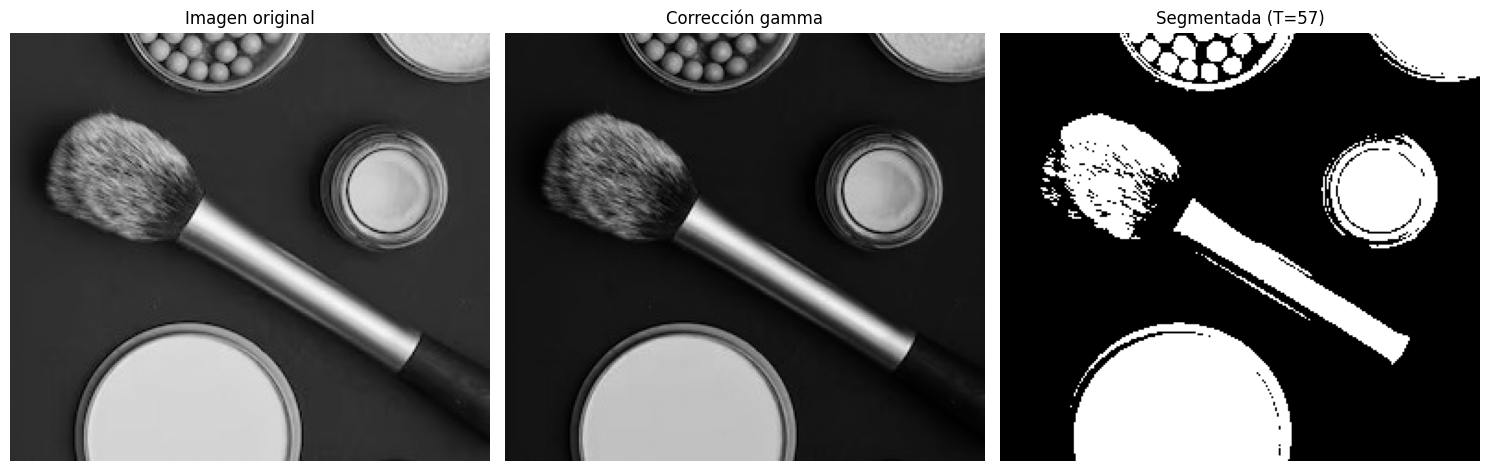

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen en escala de grises
og = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_COLOR_RGB)
imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)
# Corrección Gamma
gamma = 1.5
imagen_gamma = np.power(imagen / 255.0, gamma) * 255
imagen_gamma = np.uint8(imagen_gamma)

hipercubica = np.uint8(255 * (imagen / 255) ** 4)


def entropia_kapur(histograma, total_pixeles):
    max_entropia = -np.inf
    umbral_optimo = 0

    # Probabilidades del histograma
    prob = histograma.astype(np.float64) / total_pixeles

    for t in range(256):

        # Clase 1: intensidades de 0 a t
        clase1 = prob[:t + 1]

        # Clase 2: intensidades de t+1 a 255
        clase2 = prob[t + 1:]

        p1 = np.sum(clase1)
        p2 = np.sum(clase2)

        # Evitar clases vacías
        if p1 == 0 or p2 == 0:
            continue

        # Normalizar las probabilidades de cada clase
        prob1 = clase1 / p1
        prob2 = clase2 / p2

        # Ignorar probabilidades iguales a cero
        prob1 = prob1[prob1 > 0]
        prob2 = prob2[prob2 > 0]

        # Entropías de Kapur
        entropia1 = -np.sum(prob1 * np.log(prob1))
        entropia2 = -np.sum(prob2 * np.log(prob2))

        # Kapur maximiza la suma de las entropías
        entropia_total = entropia1 + entropia2

        if entropia_total > max_entropia:
            max_entropia = entropia_total
            umbral_optimo = t

    return umbral_optimo


# Calcular histograma
histograma, _ = np.histogram(
    imagen_gamma, bins=256, range=(0, 256)
)
total_pixeles = imagen_gamma.size

# Calcular umbral
umbral_kapur = entropia_kapur(histograma, total_pixeles)

# Segmentar: fondo blanco y objeto negro
imagen_kapur = np.where(
    imagen_gamma > umbral_kapur, 255, 0
).astype(np.uint8)

print("Umbral de Kapur:", umbral_kapur)

# Mostrar resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_gamma, cmap="gray", vmin=0, vmax=255)
plt.title("Corrección gamma")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_kapur, cmap="gray", vmin=0, vmax=255)
plt.title(f"Segmentada (T={umbral_kapur})")
plt.axis("off")

plt.tight_layout()
plt.show()

Número de objetos detectados con vecindad-4: 137
Número de objetos detectados con vecindad-8: 48


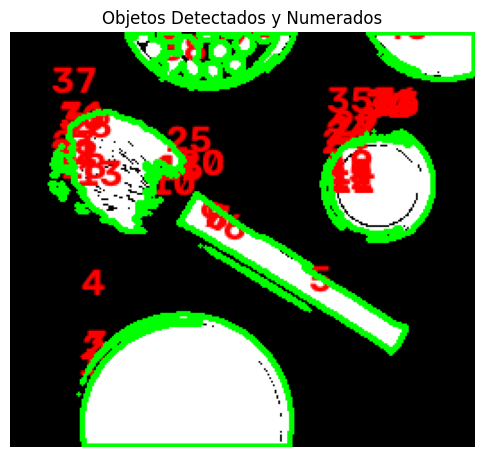

Diferencia entre vecindad-4 y vecindad-8: 89


In [5]:

# ----- 2. Etiquetado de componentes conexas -----
# Vecindad-4
num_labels_4, labels_4 = cv2.connectedComponents(imagen_kapur, connectivity=4)
# Vecindad-8
num_labels_8, labels_8 = cv2.connectedComponents(imagen_kapur, connectivity=8)
print(f"Número de objetos detectados con vecindad-4: {num_labels_4 - 1}")
print(f"Número de objetos detectados con vecindad-8: {num_labels_8 - 1}")

# ----- 3. Dibujar contornos y numerar los objetos -----

# Convertir imagen binaria a imagen en color para dibujar contornos
image_color = cv2.cvtColor(imagen_kapur, cv2.COLOR_GRAY2BGR)

# Encontrar contornos en la imagen
contours, _ = cv2.findContours(imagen_kapur, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Dibujar los contornos y numerar los objetos
for i, contour in enumerate(contours):
    # Dibujar contorno (color verde)
    cv2.drawContours(image_color, [contour], -1, (0, 255, 0), 2)
    # Encontrar el centro del objeto y colocar el número
    x, y, w, h = cv2.boundingRect(contour)
    cv2.putText(image_color, f'{i + 1}', (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

# Mostrar la imagen con los contornos y etiquetas
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB))
plt.title('Objetos Detectados y Numerados')
plt.axis('off')
plt.show()
# ----- 4. Comparación entre vecindad-4 y vecindad-8 -----
diferencia = abs(num_labels_4 - num_labels_8)
print(f"Diferencia entre vecindad-4 y vecindad-8: {diferencia}")